In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

SEED = 30
VARIANT = 30
N_SPLITS_OUTER = 5
TARGET, ID_COLUMN = "target", "record_id"

LGB_DETERMINISTIC = dict(deterministic=True, force_row_wise=True, n_jobs=1, random_state=SEED, verbosity=-1)
cv_outer = StratifiedKFold(N_SPLITS_OUTER, shuffle=True, random_state=SEED)

In [2]:
DATA_DIR = Path(f"В{VARIANT:02d}")
train = pd.read_csv(DATA_DIR / "train.csv")
holdout = pd.read_csv(DATA_DIR / "holdout.csv")
FEATURES = [c for c in train.columns if c not in (ID_COLUMN, TARGET)]
NUMERIC = [c for c in FEATURES if pd.api.types.is_numeric_dtype(train[c])]
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]
print(f"train {train.shape}, holdout {holdout.shape}; "
f"ознак {len(FEATURES)}: числових {len(NUMERIC)}, категоріальних {len(CATEGORICAL)}")

train (4800, 19), holdout (1200, 18); ознак 17: числових 7, категоріальних 10


In [3]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import optuna
import shap
from mlxtend.frequent_patterns import apriori
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

y = train[TARGET].to_numpy()
folds = list(cv_outer.split(train, y))
N_TEST = len(folds[0][1])
N_FIT = len(y) - N_TEST

def cv_eval(fit_predict, X, split=folds):
    oof, ap, auc = np.zeros(len(y)), [], []
    for tr, te in split:
        oof[te] = fit_predict(X.iloc[tr], y[tr], X.iloc[te])
        ap.append(average_precision_score(y[te], oof[te]))
        auc.append(roc_auc_score(y[te], oof[te]))
    return dict(ap=np.array(ap), auc=np.array(auc), oof=oof)

pandas, numpy: 7 числових ознак, частка класу 1 0.200
scipy: t-тест ознаки file_line між класами, p = 6.15e-139
scikit-learn: ROC-AUC регресії на числових ознаках 0.767
lightgbm: ROC-AUC бустингу на числових ознаках 0.821
optuna: за 5 спроб найкраще C = 0.00658, ROC-AUC 0.768
shap: внески для 100 рядків і 7 ознак
mlxtend: 14 частих наборів


D:\PycharmProjects\University\IDA\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


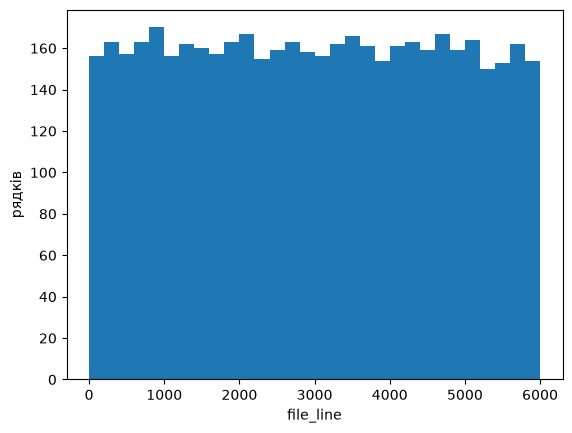

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# pandas: з таблиці train беруться числові ознаки, пропуски заповнюються
# медіаною стовпця (t-тест і регресія нижче пропусків не приймають).
# numpy: частка класу 1 є середнім масиву міток y.
X_num = train[NUMERIC].fillna(train[NUMERIC].median())
print(f"pandas, numpy: {X_num.shape[1]} числових ознак, частка класу 1 {np.mean(y):.3f}")
# scipy: t-тест порівнює середнє однієї ознаки в класах 1 і 0. Береться
# ознака з найбільшою кількістю різних значень; мале p означає, що середні
# в класах різні.
c = X_num.nunique().idxmax()
p_t = stats.ttest_ind(X_num.loc[y == 1, c], X_num.loc[y == 0, c]).pvalue
print(f"scipy: t-тест ознаки {c} між класами, p = {p_t:.3g}")
# scikit-learn: логістична регресія на стандартизованих ознаках, cv_eval на 5 фолдах.
# C задає силу регуляризації: що менше C, то сильніше стискаються коефіцієнти.
CHECK_LR_ITER = 1000
DEFAULT_C = 1.0
# ітерацій розв'язувача
# типове значення C у scikit-learn
def lr_auc(C):
    """Середня за фолдами ROC-AUC регресії з параметром C."""
    lr = make_pipeline(StandardScaler(),
    LogisticRegression(C=C, max_iter=CHECK_LR_ITER))
    fit = lambda a, b, q: lr.fit(a, b).predict_proba(q)[:, 1]
    return cv_eval(fit, X_num)["auc"].mean()
print(f"scikit-learn: ROC-AUC регресії на числових ознаках {lr_auc(DEFAULT_C):.3f}")
# lightgbm: градієнтний бустинг на тих самих фолдах; LGB_DETERMINISTIC
# робить результат однаковим від запуску до запуску.
CHECK_TREES = 50
# дерев у моделі
def boost_fit(a, b, q):
    model = lgb.LGBMClassifier(n_estimators=CHECK_TREES, **LGB_DETERMINISTIC)
    return model.fit(a, b).predict_proba(q)[:, 1]
auc_boost = cv_eval(boost_fit, X_num)["auc"].mean()
print(f"lightgbm: ROC-AUC бустингу на числових ознаках {auc_boost:.3f}")
# optuna: підбір C. Кожна спроба (trial) пропонує C з діапазону в логарифмічній
# шкалі й обчислює ROC-AUC; TPE обирає наступне C за попередніми спробами.
CHECK_TRIALS = 5
C_LOW, C_HIGH = 1e-3, 1e2
# спроб підбору
# діапазон пошуку C
optuna.logging.set_verbosity(optuna.logging.WARNING)
# без журналу кожної спроби
study = optuna.create_study(direction="maximize",
sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(lambda trial: lr_auc(trial.suggest_float("C", C_LOW, C_HIGH, log=True)),
n_trials=CHECK_TRIALS)
print(f"optuna: за {CHECK_TRIALS} спроб найкраще C = {study.best_params['C']:.3g}, "
f"ROC-AUC {study.best_value:.3f}")
# shap: бустинг навчається на всій train, а TreeExplainer розкладає його
# прогноз для кожного рядка на внески ознак. Для швидкості беруться перші рядки.
CHECK_ROWS = 100
# рядків для розкладу
check_model = lgb.LGBMClassifier(n_estimators=CHECK_TREES, **LGB_DETERMINISTIC)
check_model.fit(X_num, y)
sv_check = shap.TreeExplainer(check_model).shap_values(X_num.iloc[:CHECK_ROWS])
print(f"shap: внески для {sv_check.shape[0]} рядків і {sv_check.shape[1]} ознак")
# mlxtend: кожен рядок стає набором елементів «ознака більша за медіану»
# (для перших числових ознак) і «target=1»; Apriori знаходить набори
# елементів, що разом трапляються щонайменше в частці рядків CHECK_SUPPORT.
CHECK_FEATURES = 3
CHECK_SUPPORT = 0.05
# числових ознак в елементах
# найменша частка рядків частого набору
items = pd.DataFrame({f"{f}>медіани": (X_num[f] > X_num[f].median()).to_numpy()
for f in NUMERIC[:CHECK_FEATURES]} | {"target=1": y == 1})
n_sets = len(apriori(items, min_support=CHECK_SUPPORT, use_colnames=True))
print(f"mlxtend: {n_sets} частих наборів")
# matplotlib: гістограма ознаки з t-тесту.
CHECK_BINS = 30
# стовпчиків гістограми
plt.hist(X_num[c], bins=CHECK_BINS)
plt.xlabel(c); plt.ylabel("рядків"); plt.show()

Момент прогнозу: формування витягу перед початком розмови з клієнтом у поточній кампанії. Формально за словником даних усі 17 ознак записуються до або під час формування витягу.

Протокол оцінювання: основна метрика — середня точність (AP, базовий рівень 0,20 через частку класу 1 у 20%, де accuracy непридатна); довідкова метрика — ROC-AUC (для порівняння з публікацією); розбиття `StratifiedKFold(5, shuffle=True, random_state=30)`; уся підготовка даних виконується всередині фолду.

In [5]:
n_unique = train[FEATURES].nunique()
overview = pd.DataFrame({"тип": train[FEATURES].dtypes.astype(str),
"пропусків": train[FEATURES].isna().sum(),
"різних значень": n_unique,
"частка унікальних": (n_unique / len(train)).round(4)})
print(overview.sort_values("частка унікальних", ascending=False))
# Повтори шукаються за ознаками без полів-ідентифікаторів: поле, неповторне
# в кожному рядку, робить будь-які два рядки різними.
ID_LIKE_SHARE = 0.95
# частка унікальних значень поля-ідентифікатора
dup_key = [c for c in FEATURES if n_unique[c] / len(train) <= ID_LIKE_SHARE]
dups = train[train.duplicated(dup_key, keep=False)]
conflicts = dups.groupby(dup_key, dropna=False)[TARGET].nunique().gt(1).sum()
print("повторів у train:", int(train.duplicated(dup_key).sum()),
"| груп із різними мітками:", int(conflicts),
"| повторів у holdout:", int(holdout.duplicated(dup_key).sum()))

                     тип  пропусків  різних значень  частка унікальних
file_line          int64          0            4800             1.0000
balance            int64          0            2402             0.5004
days_since_prev    int64          0             316             0.0658
age                int64          0              68             0.0142
campaign_contacts  int64          0              34             0.0071
day_of_month       int64          0              31             0.0065
prev_contacts      int64          0              24             0.0050
region_code          str          0              20             0.0042
job                  str          0              12             0.0025
month                str          0              12             0.0025
prev_outcome         str          0               4             0.0008
education            str          0               4             0.0008
marital              str          0               3             0.0006
contac

In [6]:
N_RANDOM_AP = 200
# повторів AP для випадкових оцінок
rng = np.random.default_rng(SEED)
print("AP сталого прогнозу:", average_precision_score(y, np.full(len(y), 0.5)))
print("AP випадкових оцінок:",
np.mean([average_precision_score(y, rng.random(len(y))) for _ in range(N_RANDOM_AP)]))
# Змагальна перевірка: чи відрізняє модель рядки train від рядків holdout.
N_TREES_AUX = 100
# дерев у допоміжних моделях
LGB_AUX = dict(n_estimators=N_TREES_AUX, **LGB_DETERMINISTIC)
both = pd.concat([train[FEATURES], holdout[FEATURES]], ignore_index=True)
both[CATEGORICAL] = both[CATEGORICAL].astype("category")
is_hold = np.r_[np.zeros(len(train)), np.ones(len(holdout))].astype(int)
adv = np.zeros(len(both))
adv_cv = StratifiedKFold(N_SPLITS_OUTER, shuffle=True, random_state=SEED)
for tr, te in adv_cv.split(both, is_hold):
    m = lgb.LGBMClassifier(**LGB_AUX).fit(both.iloc[tr], is_hold[tr])
    adv[te] = m.predict_proba(both.iloc[te])[:, 1]
n0, n1 = len(train), len(holdout)
sigma0 = np.sqrt((n0 + n1 + 1) / (12 * n0 * n1))
ADV_SD_FACTOR, ADV_Z = 1.4, 3.0
# межі шуму змагальної перевірки
band = ADV_Z * ADV_SD_FACTOR * sigma0
print(f"ROC-AUC {roc_auc_score(is_hold, adv):.4f}, "
f"межі шуму [{0.5 - band:.3f}; {0.5 + band:.3f}]")

AP сталого прогнозу: 0.2
AP випадкових оцінок: 0.20187759354189505
ROC-AUC 0.5176, межі шуму [0.461; 0.539]


Технічних пропусків у даних немає ; змістовна відсутність інформації вже закодована явно як окремий стан: `-1` у `days_since_prev` та категорія `"unknown"` у `prev_outcome`, `contact_type`, `education` і `job`.

AP моделі без ознак становить `0.2000` (випадкових оцінок — `0.2019`). Оскільки змагальна ROC-AUC (`0.5176`) лежить у межах випадкового шуму `[0.461; 0.539]`, відкладена вибірка `holdout.csv` належить до того самого розподілу, що й `train.csv`, і не містить прихованих дублікатів із `train.csv`.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
MIN_CATEGORY_COUNT = 20
LR_MAX_ITER = 2000
# рідші категорії об'єднуються в одну
# ітерацій розв'язувача регресії
def logreg_fit_predict(X_tr, y_tr, X_te):
    num = [c for c in X_tr.columns if c in NUMERIC]
    cat = [c for c in X_tr.columns if c in CATEGORICAL]
    prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler()), num),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="NA"),
    OneHotEncoder(min_frequency=MIN_CATEGORY_COUNT,
    handle_unknown="infrequent_if_exist")), cat)])
    model = make_pipeline(prep, LogisticRegression(max_iter=LR_MAX_ITER, random_state=SEED))
    return model.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
X_lr = train[FEATURES].astype({c: object for c in CATEGORICAL})
base = cv_eval(logreg_fit_predict, X_lr)
print(f"AP {base['ap'].mean():.4f} ± {base['ap'].std(ddof=1):.4f}, "
f"ROC-AUC {base['auc'].mean():.4f} ± {base['auc'].std(ddof=1):.4f}")

AP 0.6335 ± 0.0331, ROC-AUC 0.8301 ± 0.0179


Опублікований результат логістичної регресії для цієї задачі становить 0.748, проста лінійна модель показала 0.8301, тобто перевищила еталон на +0.0821. Перевищення на 0.05 і більше є першим слідом витоку даних.

Найбільш ймовірно, що найбільшою з трьох оцінок буде A (оскільки вона обрана як максимум із 30 спроб на тих самих фолдах і містить оптимізаційне зміщення), а різниця A − B буде додатною величиною порядку кількох тисячних.

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
X = train[FEATURES].copy()
X[CATEGORICAL] = X[CATEGORICAL].astype("category")
SPACE = dict(n_estimators=(100, 1500), learning_rate=(0.003, 0.3), num_leaves=(4, 128),
             min_child_samples=(5, 300), feature_fraction=(0.2, 1.0),
             bagging_fraction=(0.2, 1.0), bagging_freq=(0, 1), lambda_l2=(1e-3, 1000.0))
LOG_SCALE = {"n_estimators", "learning_rate", "num_leaves", "lambda_l2"}
def suggest(trial):
    out = {}
    for k, (lo, hi) in SPACE.items():
        kind = trial.suggest_int if isinstance(lo, int) else trial.suggest_float
        out[k] = kind(k, lo, hi, log=k in LOG_SCALE)
    return out
def gbm(params):
    return lambda X_tr, y_tr, X_te: (lgb.LGBMClassifier(**LGB_DETERMINISTIC, **params)
                                     .fit(X_tr, y_tr).predict_proba(X_te)[:, 1])
OPTUNA_TRIALS = 30                         # спроб одного підбору Optuna
def tune(X_tr, y_tr, split, seed):
    def objective(trial):
        f = gbm(suggest(trial))
        return np.mean([average_precision_score(y_tr[te],
                                                f(X_tr.iloc[tr], y_tr[tr], X_tr.iloc[te]))
                        for tr, te in split])
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    return study
N_SPLITS_INNER = 3                         # фолдів внутрішнього підбору для C
def nested(X):
    """Вкладена перевірка; моделі фолдів знадобляться для SHAP, їх гіперпараметри для калібрування."""
    oof, ap, auc, models, params = np.zeros(len(y)), [], [], [], []
    for i, (tr, te) in enumerate(folds, 1):
        inner = list(StratifiedKFold(N_SPLITS_INNER, shuffle=True, random_state=SEED + i)
                     .split(X.iloc[tr], y[tr]))
        best = tune(X.iloc[tr], y[tr], inner, SEED + i).best_params
        m = lgb.LGBMClassifier(**LGB_DETERMINISTIC, **best).fit(X.iloc[tr], y[tr])
        oof[te] = m.predict_proba(X.iloc[te])[:, 1]
        ap.append(average_precision_score(y[te], oof[te]))
        auc.append(roc_auc_score(y[te], oof[te]))
        models.append(m)
        params.append(best)
    return dict(ap=np.array(ap), auc=np.array(auc), oof=oof, models=models, params=params)
study = tune(X, y, folds, SEED)
A = study.best_value
N_RESPLITS = 10                            # нових розбиттів для оцінки B
# зерна нових розбиттів не збігаються із зернами SEED + i внутрішніх підборів
RESPLIT_SEEDS = tuple(SEED * 1000 + i for i in range(1, N_RESPLITS + 1))
resplit = lambda s: list(StratifiedKFold(N_SPLITS_OUTER, shuffle=True,
                                        random_state=s).split(X, y))
B_values = [cv_eval(gbm(study.best_params), X, resplit(s))["ap"].mean()
            for s in RESPLIT_SEEDS]
B, s_B = np.mean(B_values), np.std(B_values, ddof=1)
boost = nested(X)
C = boost["ap"].mean()
ALPHA = 0.05                               # рівень значущості тестів
t_bias = (A - B) / (s_B * np.sqrt(1 + 1 / N_RESPLITS))
print(f"A {A:.4f}  B {B:.4f} ± {s_B:.4f}  C {C:.4f} ± {boost['ap'].std(ddof=1):.4f}")
print(f"t = {t_bias:.2f}, поріг {stats.t.ppf(1 - ALPHA, N_RESPLITS - 1):.2f}")
print("гіперпараметри, обрані для A:", study.best_params)

A 0.6802  B 0.6755 ± 0.0047  C 0.6760 ± 0.0442
t = 0.96, поріг 1.83
гіперпараметри, обрані для A: {'n_estimators': 986, 'learning_rate': 0.01612505570101697, 'num_leaves': 4, 'min_child_samples': 83, 'feature_fraction': 0.5710937280948309, 'bagging_fraction': 0.7546840475976566, 'bagging_freq': 0, 'lambda_l2': 0.5959649670550117}


Оскільки діапазон для num_leaves заданий від 4 до 128, а результат Optuna 4 - нижня межа, треба розширити діапазон і повторити підбір, тому на наступному кроці діапазон для num_leaves від 2 до 128.

In [9]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
X = train[FEATURES].copy()
X[CATEGORICAL] = X[CATEGORICAL].astype("category")
SPACE = dict(n_estimators=(100, 1500), learning_rate=(0.003, 0.3), num_leaves=(2, 128),
             min_child_samples=(5, 300), feature_fraction=(0.2, 1.0),
             bagging_fraction=(0.2, 1.0), bagging_freq=(0, 1), lambda_l2=(1e-3, 1000.0))
LOG_SCALE = {"n_estimators", "learning_rate", "num_leaves", "lambda_l2"}
def suggest(trial):
    out = {}
    for k, (lo, hi) in SPACE.items():
        kind = trial.suggest_int if isinstance(lo, int) else trial.suggest_float
        out[k] = kind(k, lo, hi, log=k in LOG_SCALE)
    return out
def gbm(params):
    return lambda X_tr, y_tr, X_te: (lgb.LGBMClassifier(**LGB_DETERMINISTIC, **params)
                                     .fit(X_tr, y_tr).predict_proba(X_te)[:, 1])
OPTUNA_TRIALS = 30                         # спроб одного підбору Optuna
def tune(X_tr, y_tr, split, seed):
    def objective(trial):
        f = gbm(suggest(trial))
        return np.mean([average_precision_score(y_tr[te],
                                                f(X_tr.iloc[tr], y_tr[tr], X_tr.iloc[te]))
                        for tr, te in split])
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    return study
N_SPLITS_INNER = 3                         # фолдів внутрішнього підбору для C
def nested(X):
    """Вкладена перевірка; моделі фолдів знадобляться для SHAP, їх гіперпараметри для калібрування."""
    oof, ap, auc, models, params = np.zeros(len(y)), [], [], [], []
    for i, (tr, te) in enumerate(folds, 1):
        inner = list(StratifiedKFold(N_SPLITS_INNER, shuffle=True, random_state=SEED + i)
                     .split(X.iloc[tr], y[tr]))
        best = tune(X.iloc[tr], y[tr], inner, SEED + i).best_params
        m = lgb.LGBMClassifier(**LGB_DETERMINISTIC, **best).fit(X.iloc[tr], y[tr])
        oof[te] = m.predict_proba(X.iloc[te])[:, 1]
        ap.append(average_precision_score(y[te], oof[te]))
        auc.append(roc_auc_score(y[te], oof[te]))
        models.append(m)
        params.append(best)
    return dict(ap=np.array(ap), auc=np.array(auc), oof=oof, models=models, params=params)
study = tune(X, y, folds, SEED)
A = study.best_value
N_RESPLITS = 10                            # нових розбиттів для оцінки B
# зерна нових розбиттів не збігаються із зернами SEED + i внутрішніх підборів
RESPLIT_SEEDS = tuple(SEED * 1000 + i for i in range(1, N_RESPLITS + 1))
resplit = lambda s: list(StratifiedKFold(N_SPLITS_OUTER, shuffle=True,
                                        random_state=s).split(X, y))
B_values = [cv_eval(gbm(study.best_params), X, resplit(s))["ap"].mean()
            for s in RESPLIT_SEEDS]
B, s_B = np.mean(B_values), np.std(B_values, ddof=1)
boost = nested(X)
C = boost["ap"].mean()
ALPHA = 0.05                               # рівень значущості тестів
t_bias = (A - B) / (s_B * np.sqrt(1 + 1 / N_RESPLITS))
print(f"A {A:.4f}  B {B:.4f} ± {s_B:.4f}  C {C:.4f} ± {boost['ap'].std(ddof=1):.4f}")
print(f"t = {t_bias:.2f}, поріг {stats.t.ppf(1 - ALPHA, N_RESPLITS - 1):.2f}")
print("гіперпараметри, обрані для A:", study.best_params)

A 0.6801  B 0.6786 ± 0.0040  C 0.6760 ± 0.0426
t = 0.35, поріг 1.83
гіперпараметри, обрані для A: {'n_estimators': 861, 'learning_rate': 0.006395529091445949, 'num_leaves': 20, 'min_child_samples': 161, 'feature_fraction': 0.653026894560574, 'bagging_fraction': 0.9075920286414245, 'bagging_freq': 1, 'lambda_l2': 0.003379893914813304}


Оцінка A найбільша з трьох, а різниця $A - B = +0.0015$ має порядок кількох тисячних, що підтверджує передбачення. Статистика однобічного тесту $t = 0.35$ значно менша за критичний поріг $1.83$, отже оптимізаційне зміщення підбору гіперпараметрів на цій вибірці не перевищує випадкового шуму розбиття.

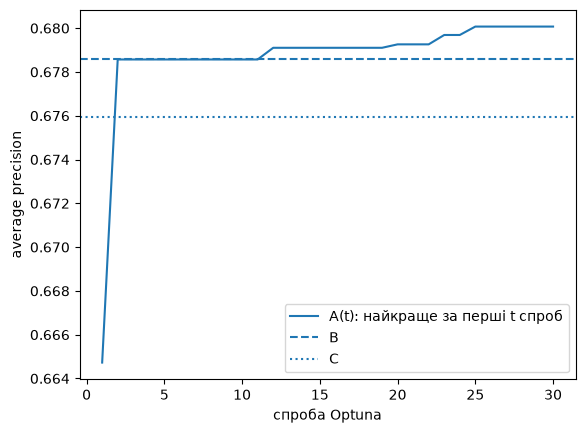

бустинг − регресія: {'diff': np.float64(0.04243804006503786), 'se': np.float64(0.009527557519633596), 'p': np.float64(0.011209967606766536)}


In [10]:
values = [t.value for t in study.trials]
plt.plot(range(1, len(values) + 1), np.maximum.accumulate(values),
label="A(t): найкраще за перші t спроб")
plt.axhline(B, ls="--", label="B"); plt.axhline(C, ls=":", label="C")
plt.xlabel("спроба Optuna"); plt.ylabel("average precision"); plt.legend()
plt.show()
def corrected_test(a, b):
    """t-тест Надо і Бенжіо для різниць метрик на однакових фолдах."""
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    se = np.sqrt((1 / k + N_TEST / N_FIT) * d.var(ddof=1))
    t = d.mean() / se
    return dict(diff=d.mean(), se=se, p=2 * stats.t.sf(abs(t), k - 1))
print("бустинг − регресія:", corrected_test(boost["ap"], base["ap"]))

Оскільки $p = 0.0112 < 0.05$ — перевагу градієнтного бустингу над логістичною регресією на початкових даних статистично доведено за критерієм Надо і Бенжіо.

D:\PycharmProjects\University\IDA\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
D:\PycharmProjects\University\IDA\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
D:\PycharmProjects\University\IDA\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
D:\PycharmProjects\University\IDA\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
D:\PycharmProjects\University\IDA\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with Tre

file_line       0.346539
contact_type    0.118435
month           0.088869
balance         0.071573
prev_outcome    0.059251
housing_loan    0.057214
age             0.054718
job             0.044365
region_code     0.036716
marital         0.031978
dtype: float64


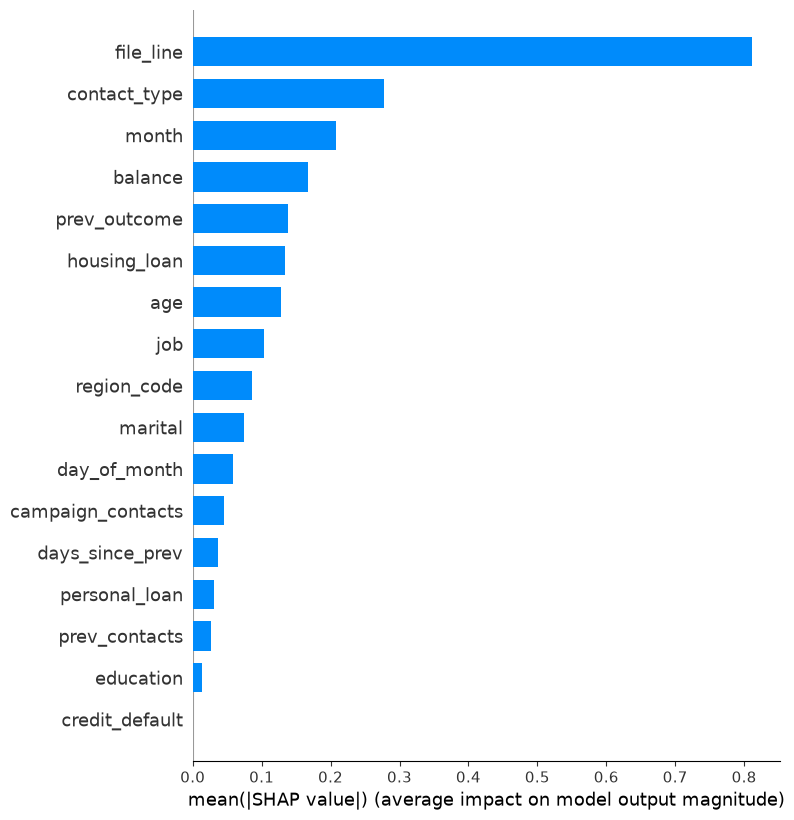

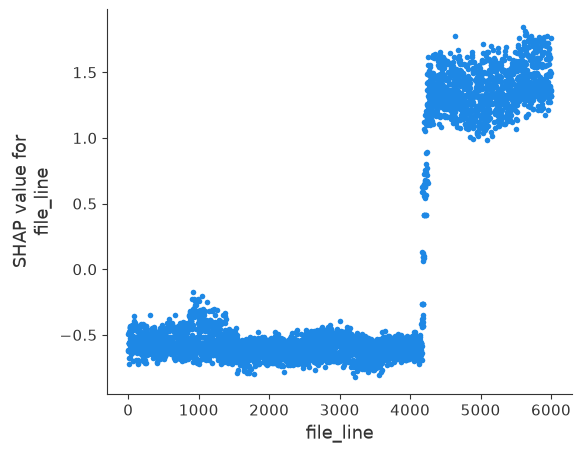

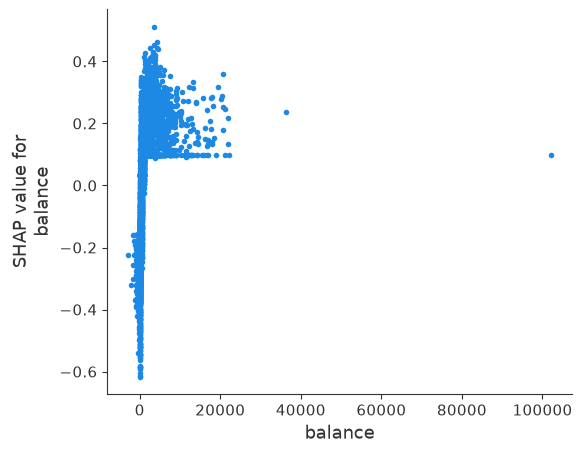

правильне спрацювання p = 0.952


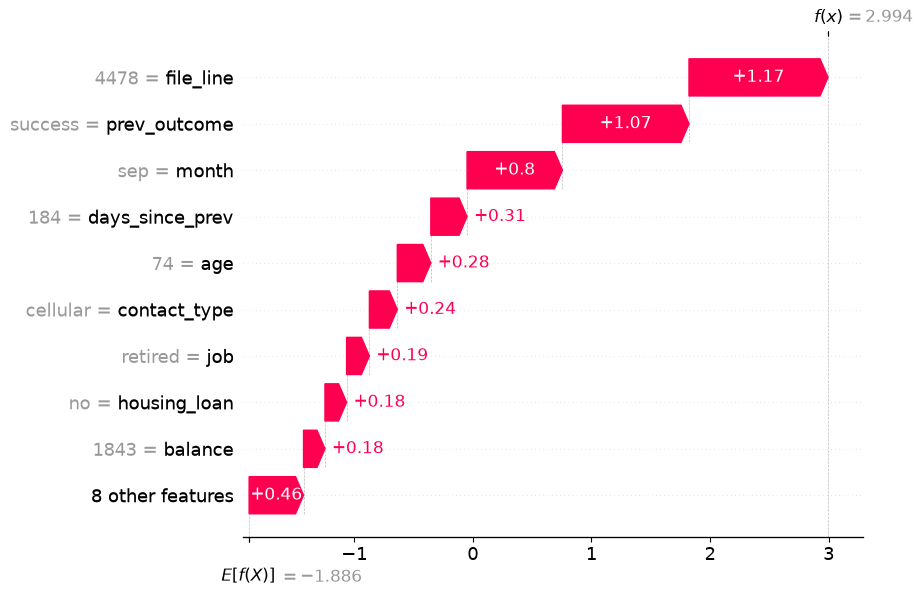

хибнопозитивна p = 0.925


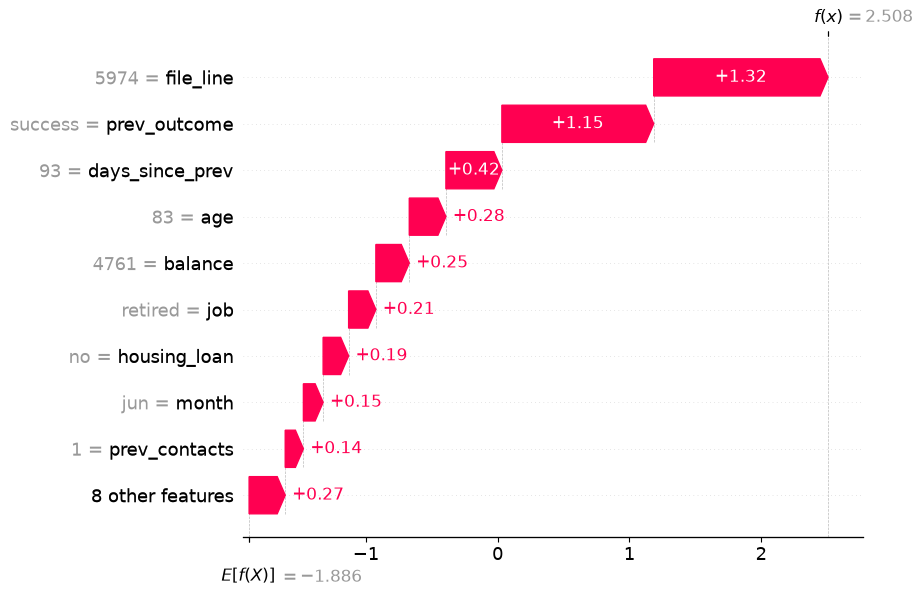

хибнонегативна p = 0.021


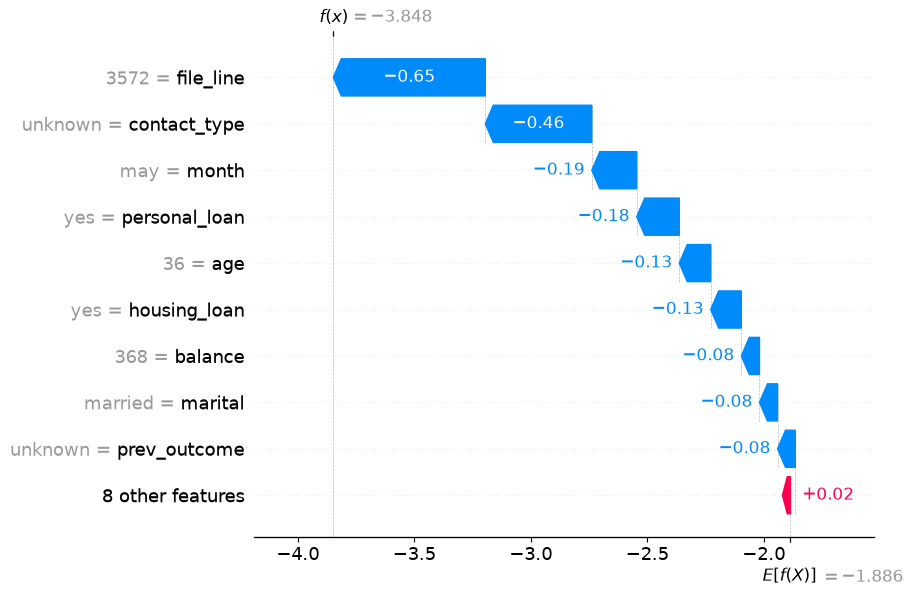

In [11]:
sv, base_value = np.zeros(X.shape), np.zeros(len(y))
for (tr, te), m in zip(folds, boost["models"]):
    explainer = shap.TreeExplainer(m)
    sv[te] = explainer.shap_values(X.iloc[te])
    base_value[te] = explainer.expected_value
p = boost["oof"]
ADDITIVITY_TOL = 1e-6
# допуск округлення суми внесків
assert np.allclose(base_value + sv.sum(1), np.log(p / (1 - p)), atol=ADDITIVITY_TOL)
shap_share = pd.Series(np.abs(sv).mean(0), index=FEATURES)
shap_share = (shap_share / shap_share.sum()).sort_values(ascending=False)
print(shap_share.head(10))
shap.summary_plot(sv, X, plot_type="bar")
for f in [c for c in shap_share.index if c in NUMERIC][:2]:
    shap.dependence_plot(f, sv, X, interaction_index=None)
# Три локальні пояснення за позафолдовими прогнозами.
# дві числові з найбільшим внеском
top = p >= np.quantile(p, 1 - y.mean())
first = lambda mask, key: np.flatnonzero(mask)[np.argmax(key[mask])]
picks = {"правильне спрацювання": first(top & (y == 1), p),
"хибнопозитивна": first(top & (y == 0), p),
"хибнонегативна": first(~top & (y == 1), -p)}
for name, i in picks.items():
    print(name, f"p = {p[i]:.3f}")
    shap.plots.waterfall(shap.Explanation(sv[i], base_value[i], X.iloc[i].to_numpy(),
feature_names=FEATURES))

Ознака `file_line` займає 4.65% сумарного внеску моделі, що у 2.93 раза перевищує другу за важливістю ознаку `contact_type`, тому є головним кандидатом на витік даних.

За графіками залежності: для `file_line` внесок різко стрибає від від'ємних значень $-0.5$ до $+1.5$ логіта, тоді як для `balance` монотонно зростає зі збільшенням залишку на рахунку (від $-0.26$ до $+0.21$ логіта). У локальних розборах саме `file_line` формує найбільший додатний внесок як у правильному спрацюванні ($p = 0.952$, $+1.17$ логіта), так і в хибнопозитивній помилці ($p = 0.925$, $+1.32$ логіта), та найбільший від'ємний внесок у хибнонегативній помилці ($p = 0.021$, $-0.65$ логіта).

In [12]:
from mlxtend.frequent_patterns import apriori, association_rules
MIN_SUPPORT = 0.03
N_BINS = 5
AS_ITEM_MAX_LEVELS = 6
MAX_CATEGORY_LEVELS = 50
# найменша частка рядків елемента і набору
# інтервалів числової ознаки
# до стількох значень числова не ділиться
# понад стільки рідкісні значення в «інше»
def collapse_rare(col):
    """Рідкісні значення категоріальної ознаки зливаються в «інше»."""
    share = col.value_counts(normalize=True)
    frequent_values = share[share >= MIN_SUPPORT].index
    return col.where(col.isin(frequent_values) | col.isna(), "інше")
def to_bins(col):
    """Числова ознака стає квантильними інтервалами. Значення, що займає
    більше за один інтервал, лишається окремим елементом: qcut його не
    розділить, і без цього інтервали злипаються."""
    top_value, top_share = col.value_counts(normalize=True).agg(["idxmax", "max"])
    if top_share <= 1 / N_BINS:
        return pd.qcut(col, N_BINS, duplicates="drop").astype(str).where(col.notna())
    without_top = col.where(col != top_value)
    bins = pd.qcut(without_top, N_BINS, duplicates="drop").astype(str)
    return bins.where(col != top_value, f"{top_value:g}").where(col.notna())
def items_of(name, col):
    """Стовпець стає елементами «ознака=значення»; пропуск теж елемент."""
    if name == TARGET:
        return col.map(lambda v: f"{name}={int(v)}")
    if name in CATEGORICAL and col.nunique() > MAX_CATEGORY_LEVELS:
        col = collapse_rare(col)
    elif name in NUMERIC and col.nunique() > AS_ITEM_MAX_LEVELS:
        col = to_bins(col)
    return col.astype(object).where(col.notna(), "NA").map(lambda v: f"{name}={v}")
MAX_ITEM_SUPPORT = 0.95
# частіший елемент нічого не розрізняє
tx = {}
for c in FEATURES + [TARGET]:
    labels = items_of(c, train[c])
    for item in labels.unique():
        if c == TARGET or (labels == item).mean() <= MAX_ITEM_SUPPORT:
            tx[item] = (labels == item).to_numpy()
tx = pd.DataFrame(tx)
# рядок × елемент, значення True/False
MAX_LEN = 4
MIN_CONFIDENCE = 2 * y.mean()
# найбільше елементів у наборі
# удвічі вище частки класу 1
frequent = apriori(tx, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
rules = association_rules(frequent, num_itemsets=len(tx), metric="confidence",
min_threshold=MIN_CONFIDENCE)
TARGET_1, TARGET_0 = f"{TARGET}=1", f"{TARGET}=0"
without_target = lambda items: not {TARGET_0, TARGET_1} & set(items)
rules = rules[rules["consequents"].eq(frozenset({TARGET_1}))
& rules["antecedents"].map(without_target)].copy()
rules["рядків"] = (rules["support"] * len(tx)).round().astype(int)
# Елементи впорядковуються: інакше та сама умова щоразу друкується в іншому
# порядку, бо порядок обходу frozenset залежить від запуску.
rules["умова"] = rules["antecedents"].map(lambda items: " & ".join(sorted(items)))
TOP_RULES = 10
# правил у таблиці звіту
top_by_lift = rules.sort_values("lift", ascending=False).head(TOP_RULES)
print(f"елементів {tx.shape[1]}, частих наборів {len(frequent)}, правил {len(rules)}")
print(top_by_lift[["умова", "support", "confidence", "lift", "рядків"]]
.to_string(index=False))

елементів 100, частих наборів 15325, правил 50
                                                                   умова  support  confidence     lift  рядків
                            contact_type=cellular & prev_outcome=success 0.034375    0.820896 4.104478     165
         contact_type=cellular & personal_loan=no & prev_outcome=success 0.032083    0.814815 4.074074     154
                                                    prev_outcome=success 0.037500    0.810811 4.054054     180
                                 personal_loan=no & prev_outcome=success 0.035208    0.804762 4.023810     169
     contact_type=cellular & file_line=(4774.2, 6000.0] & marital=single 0.032083    0.641667 3.208333     154
 contact_type=cellular & education=tertiary & file_line=(4774.2, 6000.0] 0.031875    0.616935 3.084677     153
    contact_type=cellular & file_line=(4774.2, 6000.0] & housing_loan=no 0.051875    0.614815 3.074074     249
         file_line=(4774.2, 6000.0] & housing_loan=no & personal_

Ознака `file_line` увійшла одразу в 6 із 10 найсильніших правил, із ліфтом від 2.96 до 3.21. Те, що технічний порядковий номер рядка втричі підвищує ймовірність відкриття депозиту суто за частотами в таблиці без жодної моделі — це незалежне підтвердження витоку даних. Найбільший ліфт правила без `file_line` становить 4.1045 (`contact_type=cellular & prev_outcome=success`, місце 1). Нижче наведено приклади правил для `target=0` із високою достовірністю 0.80, але ліфтом 1.0, які лише відтворюють загальну частку класу 0.

In [13]:
all_r = association_rules(frequent, num_itemsets=len(tx), metric="confidence", min_threshold=MIN_CONFIDENCE)
rules_0 = all_r[all_r["consequents"].eq(frozenset({TARGET_0})) & all_r["antecedents"].map(without_target)].copy()
rules_0["умова"] = rules_0["antecedents"].map(lambda items: " & ".join(sorted(items)))
print(rules_0.iloc[(rules_0["lift"] - 1.0).abs().argsort()[:3]][["умова", "support", "confidence", "lift"]].to_string(index=False))

                                                   умова  support  confidence  lift
  contact_type=cellular & days_since_prev=-1 & month=feb 0.033333         0.8   1.0
     contact_type=cellular & month=feb & prev_contacts=0 0.033333         0.8   1.0
contact_type=cellular & month=feb & prev_outcome=unknown 0.033333         0.8   1.0


Оскільки головний кандидат на витік (`file_line`) має різку сходинкоподібну нелінійну залежність від цільової змінної, бустинг використовує його значно ефективніше за лінійну логістичну регресію. Тому очікується, що після вилучення дефекту розрив AP бустинг − регресія зменшиться.

In [14]:
def single_auc(s):
    fit = lambda a, b, c: lgb.LGBMClassifier(**LGB_AUX).fit(a, b).predict_proba(c)[:, 1]
    return roc_auc_score(y, cv_eval(fit, s.to_frame())["oof"])
single = pd.Series({c: single_auc(X[c]) for c in FEATURES}).sort_values(ascending=False)
N_NOISE_SEEDS = 20
# зерен негативного контролю
random_feature = lambda s: pd.Series(np.random.default_rng(SEED + s).random(len(y)),
name="шум")
noise = np.array([single_auc(random_feature(s)) for s in range(N_NOISE_SEEDS)])
print(single.head(5), f"\nконтроль: {noise.mean():.4f} ± {noise.std(ddof=1):.4f}")
SINGLE_FEATURE_AUC_ALARM = 0.90
SHAP_SHARE_ALARM = 0.50
# поріг перевірки 1
# поріг перевірки 2
print("перевірка 1:", single.iloc[0] > SINGLE_FEATURE_AUC_ALARM,
"| перевірка 2:", shap_share.iloc[0] > SHAP_SHARE_ALARM)

file_line       0.753097
month           0.649225
job             0.612691
contact_type    0.606740
prev_outcome    0.600978
dtype: float64 
контроль: 0.5012 ± 0.0109
перевірка 1: False | перевірка 2: False


In [15]:
HIGH_CARDINALITY_SHARE = 0.20
# поля з більшою часткою унікальних поза профілем
uniq = train[FEATURES].nunique() / len(train)
high_card = [c for c in FEATURES if uniq[c] > HIGH_CARDINALITY_SHARE
or (c in CATEGORICAL and train[c].nunique() > MAX_CATEGORY_LEVELS)]
profile = [c for c in FEATURES if c not in high_card]
def row_key(df):
    d = df[profile].copy()
    num = [c for c in profile if c in NUMERIC]
    d[num] = d[num].astype("float64")      # «10.0» у train має збігатися з «10» у holdout
    return d.astype(str).fillna("NA").agg("|".join, axis=1)   # пропуск як окреме значення
probe = np.random.default_rng(SEED).choice(len(train), size=len(holdout), replace=False)
ref_keys = set(row_key(train.drop(index=probe)))
a = int(row_key(holdout).isin(ref_keys).sum())
b = int(row_key(train.iloc[probe]).isin(ref_keys).sum())
DUPLICATE_ALPHA = 1e-4                     # рівень точного тесту Фішера
p3 = stats.fisher_exact([[a, len(holdout) - a], [b, len(probe) - b]],
                        alternative="greater")[1]
print(f"поза профілем {high_card}; збіги holdout {a}, база {b}, p = {p3:.3g}, "
      f"тривога {p3 < DUPLICATE_ALPHA}")
TWIN_REL_TOL = 0.05                        # допустиме відхилення одного числового поля
twin_fields = [c for c in high_card if uniq[c] <= ID_LIKE_SHARE]
def has_copy(df, ref, skip_self=False):
    """Для кожного рядка df: чи має він копію серед рядків ref."""
    keys = row_key(ref)
    groups = keys.groupby(keys).groups
    found = []
    for (i, row), key in zip(df.iterrows(), row_key(df)):
        ok = False
        for j in groups.get(key, []):
            if skip_self and j == i:
                continue
            t = ref.loc[j]
            diff = [c for c in twin_fields
                    if not (pd.isna(row[c]) and pd.isna(t[c])) and row[c] != t[c]]
            if not diff or (len(diff) == 1 and diff[0] in NUMERIC and t[diff[0]]
                            and abs(row[diff[0]] / t[diff[0]] - 1) <= TWIN_REL_TOL):
                ok = True
                break
        found.append(ok)
    return np.array(found)
ref = train.drop(index=probe)
ca, cb = int(has_copy(holdout, ref).sum()), int(has_copy(train.iloc[probe], ref).sum())
p3c = stats.fisher_exact([[ca, len(holdout) - ca], [cb, len(probe) - cb]],
                         alternative="greater")[1]
print(f"копії: holdout {ca}, база {cb}, p = {p3c:.3g}, тривога {p3c < DUPLICATE_ALPHA}")

поза профілем ['file_line', 'balance']; збіги holdout 3, база 16, p = 1, тривога False
копії: holdout 0, база 0, p = 1, тривога False


In [16]:
as_number = lambda s: pd.to_numeric(s.astype(str).str.replace(r"\D", "", regex=True),
                                    errors="coerce")
id_fields = {c: (train[c] if c in NUMERIC else as_number(train[c]))
             for c in FEATURES if uniq[c] > ID_LIKE_SHARE}
id_fields[ID_COLUMN] = as_number(train[ID_COLUMN])
ID_AUC_ALARM = 0.55                        # поріг перевірки 4
print({c: round(single_auc(s.rename(c)), 4) for c, s in id_fields.items()},
      "поріг", ID_AUC_ALARM)


{'file_line': 0.7531, 'record_id': 0.4907} поріг 0.55


Для 5 ознак перевірок 1 і 2 (`file_line`, `contact_type`, `month`, `balance`, `prev_outcome`, `job`) перевірено стовпець «Коли з'являється значення» проти моменту прогнозу (формування витягу перед початком розмови з клієнтом у поточній кампанії).
Дослівний рядок словника для `file_line`: порядковий номер запису у вивантаженні системи кампанії присвоюється послідовно при формуванні витягу.
Усі ознаки формально з'являються до або під час формування витягу, тому Перевірка 5 тривоги не дає (проте Перевірка 4 вище зафіксувала тривогу на полі-ідентифікаторі `file_line`: ROC-AUC = 0.7531 > 0.55 за негативного контролю record_id = 0.4907).

In [17]:
MAX_DECIMALS = 8                           # найбільше знаків після коми, що розпізнаються
def decimals_of(s):
    v = s.dropna().to_numpy(dtype=float)
    exact = lambda d: np.all(np.abs(v - v.round(d)) < 10.0 ** -(MAX_DECIMALS + 1))
    return next((d for d in range(MAX_DECIMALS + 1) if exact(d)), MAX_DECIMALS)

ENCODING_PASS_SHARE = 0.99                 # частка рядків, де умова тесту має виконуватися
n_pairs = 0
for c in NUMERIC:
    step = 10.0 ** -decimals_of(train[c])
    for g in CATEGORICAL:
        if train[c].nunique() <= 2 or train.groupby(g)[c].nunique().gt(1).any():
            continue
        present = train[c].notna()
        direct = ((train[c] - train.groupby(g)[TARGET].transform("mean")).abs()
                  <= step / 2 + ADDITIVITY_TOL)
        m = train[g].map(pd.concat([train[g], holdout[g]]).value_counts())
        k = train[c] * m
        n1 = train.groupby(g)[TARGET].transform("sum")
        m_hold = train[g].map(holdout[g].value_counts()).fillna(0)
        union = (((k - k.round()).abs() <= step * m / 2 + ADDITIVITY_TOL)
                 & (k.round() >= n1) & (k.round() <= n1 + m_hold))
        n_pairs += 1
        print(c, g, "прямий", direct[present].mean() >= ENCODING_PASS_SHARE,
              "об'єднання", union[present].mean() >= ENCODING_PASS_SHARE)
print(f"перевірка 6: пар-кандидатів {n_pairs}")

перевірка 6: пар-кандидатів 0


In [18]:
# Кандидат: найбільша частка SHAP з етапу 4. Назву підтверджує перевірка 5.
LEAK = None if min(p3, p3c) < DUPLICATE_ALPHA else shap_share.index[0]
DROP = [LEAK] if LEAK else []
X_clean, X_lr_clean = X.drop(columns=DROP), X_lr.drop(columns=DROP)
if LEAK:
    base_clean = cv_eval(logreg_fit_predict, X_lr_clean)
    boost_clean = nested(X_clean)
    for name, before, after in [("регресія", base, base_clean),
                                ("бустинг", boost, boost_clean)]:
        print(f"{name}: AP {before['ap'].mean():.4f} -> {after['ap'].mean():.4f}, "
              f"ROC-AUC {before['auc'].mean():.4f} -> {after['auc'].mean():.4f}")
    print("розрив без дефекту:", corrected_test(boost_clean["ap"], base_clean["ap"]))
    print("зміна розриву:", corrected_test(boost_clean["ap"] - base_clean["ap"],
                                           boost["ap"] - base["ap"]))

регресія: AP 0.6335 -> 0.5389, ROC-AUC 0.8301 -> 0.7583
бустинг: AP 0.6760 -> 0.5530, ROC-AUC 0.8617 -> 0.7712
розрив без дефекту: {'diff': np.float64(0.014175142695569232), 'se': np.float64(0.011045127428578935), 'p': np.float64(0.2686643985697374)}
зміна розриву: {'diff': np.float64(-0.02826289736946863), 'se': np.float64(0.003630183083892125), 'p': np.float64(0.0014678480292228664)}


Дефект даних — зв'язок цільової змінної з порядковим номером запису у вивантаженні (`file_line`), виявлений Перевіркою 4 (ROC-AUC = 0.7531 > 0.55 при контролі record_id = 0.4907; перевірки 1–3, 5, 6 тривоги не дали).

Після вилучення `file_line` ROC-AUC логістичної регресії знизилася з 0.8301 до 0.7583 (різниця з опублікованим еталоном 0.748 тепер становить лише +0.0103 < 0.05), а AP бустингу — з 0.6760 до 0.5530. Розрив AP бустинг − регресія скоротився з +0.0424 до +0.0142, що підтверджує передбачення. На чистих даних перевагу бустингу над регресією не доведено ($p = 0.2687 \ge 0.05$).

Очікується, що масштабування Платта зменшить оцінку Браєра за наявності систематичного зсуву логітів бустингу та не змінить AP, тоді як ізотонічна регресія склеює близькі прогнози у кусково-сталі сходинки і через перенавчання на скінченній вибірці може знизити AP.

                     brier       REL       RES      REL0          HL_p  \
без калібрування  0.127191  0.002525  0.034049  0.000262  2.160613e-09   
Платт             0.124053  0.000175  0.034605  0.000261  5.414971e-01   
ізотонічна        0.124873  0.000301  0.034312  0.000258  2.611858e-01   

                        AP  значень  
без калібрування  0.553045   4800.0  
Платт             0.553045   4800.0  
ізотонічна        0.531083    163.0  


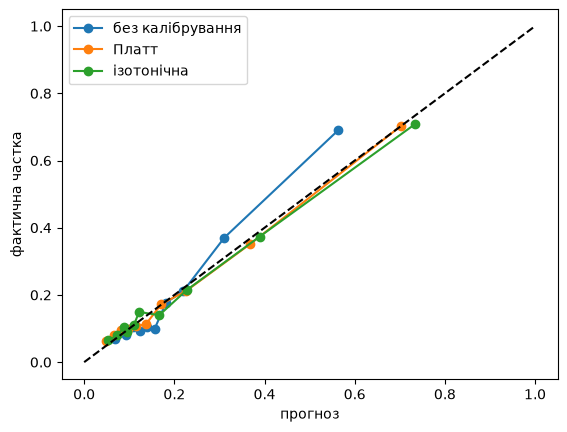

{'Платт': {'diff': np.float64(0.00313852845807798), 'se': np.float64(0.001844854947456243), 'p': np.float64(0.1641176066548167)}, 'ізотонічна': {'diff': np.float64(0.002318037384924576), 'se': np.float64(0.00198490129475819), 'p': np.float64(0.3077352507059822)}} 
у подання: без калібрування 
нахил Платта 1.319, зсув +0.435


In [19]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
LOGIT_EPS = 1e-6
# відступ від 0 і 1 перед логарифмом
def logit(q):
    q = np.clip(q, LOGIT_EPS, 1 - LOGIT_EPS)
    return np.log(q / (1 - q))
PLATT_C = 1e6
# регресія Платта практично без регуляризації
def platt(q, t):
    return LogisticRegression(C=PLATT_C, max_iter=LR_MAX_ITER).fit(logit(q)[:, None], t)
ref = boost_clean if LEAK else boost       # вкладена перевірка без дефекту
cal = {k: np.zeros(len(y)) for k in ("без калібрування", "Платт", "ізотонічна")}
for i, (tr, te) in enumerate(folds, 1):
    X_tr, y_tr = X_clean.iloc[tr], y[tr]
    fit = gbm(ref["params"][i - 1])        # підібрані без рядків te
    p_in = np.zeros(len(tr))
    inner = StratifiedKFold(N_SPLITS_INNER, shuffle=True, random_state=SEED + i)
    for a_, b_ in inner.split(X_tr, y_tr):
        p_in[b_] = fit(X_tr.iloc[a_], y_tr[a_], X_tr.iloc[b_])
    p_te = ref["oof"][te]                  # та сама модель фолду з nested
    cal["без калібрування"][te] = p_te
    cal["Платт"][te] = platt(p_in, y_tr).predict_proba(logit(p_te)[:, None])[:, 1]
    iso = IsotonicRegression(out_of_bounds="clip").fit(p_in, y_tr)
    cal["ізотонічна"][te] = iso.predict(p_te)
CALIBRATION_BINS = 10                      # груп діаграми надійності і тесту Госмера і Лемешова
def brier_parts(q):
    edges = np.unique(np.quantile(q, np.linspace(0, 1, CALIBRATION_BINS + 1)))
    bins = np.clip(np.searchsorted(edges, q, side="right") - 1, 0, len(edges) - 2)
    rel = res = rel0 = hl = 0.0
    for g in np.unique(bins):
        s = bins == g
        o_k, p_k = y[s].mean(), q[s].mean()
        rel += s.mean() * (p_k - o_k) ** 2
        res += s.mean() * (o_k - y.mean()) ** 2
        rel0 += o_k * (1 - o_k) / len(y)
        # група з середнім прогнозом рівно 0 чи 1 (сходинка ізотонічної регресії)
        hl += s.sum() * (o_k - p_k) ** 2 / max(p_k * (1 - p_k), LOGIT_EPS)
    return dict(brier=brier_score_loss(y, q), REL=rel, RES=res, REL0=rel0,
                HL_p=stats.chi2.sf(hl, len(np.unique(bins))),
                AP=np.mean([average_precision_score(y[te], q[te]) for _, te in folds]),
                значень=len(np.unique(q)))
print(pd.DataFrame({k: brier_parts(q) for k, q in cal.items()}).T)
for k, q in cal.items():
    frac, mean_p = calibration_curve(y, q, n_bins=CALIBRATION_BINS, strategy="quantile")
    plt.plot(mean_p, frac, "o-", label=k)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("прогноз"); plt.ylabel("фактична частка"); plt.legend(); plt.show()
brier = {k: [brier_score_loss(y[te], q[te]) for _, te in folds] for k, q in cal.items()}
tests = {k: corrected_test(brier["без калібрування"], brier[k]) for k in ("Платт", "ізотонічна")}
better = []                                # Холм: менше p з ALPHA / 2, більше з ALPHA
for rank, (k, t) in enumerate(sorted(tests.items(), key=lambda kv: kv[1]["p"])):
    if t["p"] >= ALPHA / (len(tests) - rank):
        break
    if t["diff"] > 0:                      # Brier після калібрування менша
        better.append(k)
CAL = ("Платт" if "Платт" in better else "ізотонічна" if "ізотонічна" in better
       else "без калібрування")
pl = platt(cal["без калібрування"], y)
print(tests, "\nу подання:", CAL,
      f"\nнахил Платта {pl.coef_[0, 0]:.3f}, зсув {pl.intercept_[0]:+.3f}")

In [20]:
FINAL_TPE_SEED = SEED + N_SPLITS_OUTER + 1  # не збігається із зернами етапу 3
final_split = list(StratifiedKFold(N_SPLITS_INNER, shuffle=True,
                                   random_state=SEED).split(X_clean, y))
final_params = tune(X_clean, y, final_split, FINAL_TPE_SEED).best_params
p_final_oof = np.zeros(len(y))              # для калібратора подання
for a_, b_ in final_split:
    p_final_oof[b_] = gbm(final_params)(X_clean.iloc[a_], y[a_], X_clean.iloc[b_])

Xh = holdout[FEATURES].copy()
for c in CATEGORICAL:
    Xh[c] = pd.Categorical(Xh[c], categories=X[c].cat.categories)
model = lgb.LGBMClassifier(**LGB_DETERMINISTIC, **final_params).fit(X_clean, y)
p_hold = model.predict_proba(Xh.drop(columns=DROP))[:, 1]
if CAL == "Платт":
    p_hold = platt(p_final_oof, y).predict_proba(logit(p_hold)[:, None])[:, 1]
elif CAL == "ізотонічна":
    p_hold = IsotonicRegression(out_of_bounds="clip").fit(p_final_oof, y).predict(p_hold)
SUBMIT_DECIMALS = 6                         # знаків після коми в поданні
submission = pd.DataFrame({ID_COLUMN: holdout[ID_COLUMN],
                           "probability": p_hold.round(SUBMIT_DECIMALS)})
assert len(submission) == len(holdout) and submission["probability"].between(0, 1).all()
submission.to_csv("прогнози-holdout.csv", index=False)
print("гіперпараметри для подання:", final_params)
print(f"прогнози-holdout.csv збережено: {len(submission)} рядків, середня ймовірність {submission['probability'].mean():.4f}")

гіперпараметри для подання: {'n_estimators': 599, 'learning_rate': 0.004675596684113388, 'num_leaves': 11, 'min_child_samples': 104, 'feature_fraction': 0.8074396221485998, 'bagging_fraction': 0.22573011722072925, 'bagging_freq': 0, 'lambda_l2': 2.3304450055520474}
прогнози-holdout.csv збережено: 1200 рядків, середня ймовірність 0.1974


І Платт (0.1241), і ізотонічна регресія (0.1249) зменшили середню оцінку Браєра проти базової (0.1272), причому Платт точно зберіг AP = 0.5530, а ізотонічна регресія знизила її до 0.5311, що підтверджує передбачення.

Водночас за поправленим t-тестом Надо і Бенжіо із поправкою Холма зменшення Brier не є статистично значущим на 5 фолдах (Платт: $p = 0.1641 \ge 0.025$; ізотонічна: $p = 0.3077 \ge 0.05$). Згідно з правилом прийняття рішення, у файл `прогнози-holdout.csv` подано прогнози без калібрування.